# Gaia with Python: TAP/ADQL, Datalink and GaiaXPy

Companion notebook for the **Gaia DR4 hands-on workshop** tutorial *TOPCAT, ADQL, Datalink and GaiaXPy*.
It repeats the TOPCAT steps in Python and adds the parts that are easier in code: Datalink retrieval,
GaiaXPy, and the exercise solutions.

Everything here uses **Gaia DR3** tables (`gaiadr3.*`). After Gaia DR4 is released (2 December 2026)
the same code should work with `gaiadr4.*` (check the DR4 data model for renamed columns).

> Generated by Claude Fable 5.1 on 2026-10-18 for Na'ama Hallakoun's workshop tutorial; all cells were executed against the live archives on that date.

**Environment:** `conda env create -f environment.yml` (astropy, astroquery, GaiaXPy ≥ 2.1.5, matplotlib, pandas, jupyterlab).

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, vstack
from astroquery.gaia import Gaia

import warnings
warnings.filterwarnings("ignore", module="astropy")  # unit warnings from Gaia columns

plt.rc("font", size=12)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


## 1. The Gaia archive from Python: `astroquery.gaia`

Documentation: https://astroquery.readthedocs.io/en/latest/gaia/gaia.html

The ESA Gaia archive is a TAP service. `Gaia.launch_job` runs a **synchronous** query (short queries only),
`Gaia.launch_job_async` runs an **asynchronous** job (the result is stored on the server and fetched when ready).

**Anonymous users have tight limits** (since the October 2026 archive upgrade an anonymous asynchronous job is
aborted after about a minute, and a synchronous query that runs longer than ~30 s returns at most 2000 rows).
Register for a free account at https://www.cosmos.esa.int/web/gaia-users/register and log in; then the same
code gets the larger registered-user quotas, your jobs are saved, and you get space for user tables.

In [2]:
# Uncomment to log in (prompts for your Cosmos user name and password; never hard-code them in a notebook).
# Gaia.login()

Gaia.ROW_LIMIT = -1          # astroquery's own cap (default 2000 rows); -1 = no client-side limit
Gaia.MAIN_GAIA_TABLE = "gaiadr3.gaia_source"

### A short synchronous query

Same query as in the TOPCAT tutorial: the nominal 100 pc sample, limited to 100 rows.

In [3]:
query_100 = """
SELECT TOP 100 *
FROM gaiadr3.gaia_source
WHERE parallax_over_error > 10
AND phot_bp_mean_flux_over_error > 10
AND phot_rp_mean_flux_over_error > 10
AND parallax > 10
"""
job = Gaia.launch_job(query_100)
top100 = job.get_results()
print(len(top100), "rows,", len(top100.colnames), "columns")
top100[["source_id", "ra", "dec", "parallax", "phot_g_mean_mag", "bp_rp", "ruwe", "has_xp_sampled"]][:5]

100 rows, 152 columns


source_id,ra,dec,parallax,phot_g_mean_mag,bp_rp,ruwe,has_xp_sampled
,deg,deg,mas,mag,mag,,
int64,float64,float64,float64,float32,float32,float32,bool
138925909806092928,46.22890116880671,35.91914002571211,16.47170464253246,14.362038,2.5097742,1.0167427,True
142132596813836160,45.45230498082764,37.55532813142934,22.823587658319738,14.332077,2.9286585,1.2882705,True
142326252594669056,45.305489838753125,37.77479936825416,12.62669752633184,14.155947,2.4393387,1.1707847,True
142780179098215424,45.32355992792882,38.44957258592414,13.454397830366311,15.907165,3.0363283,0.9854559,False
142955551202830848,46.32922649196198,39.55083705501275,13.723395799092174,15.570807,2.8850698,1.1627983,False


### The full 100 pc sample

The full query returns about 306,500 rows × 152 columns and takes a few minutes, so it needs an asynchronous job
(and a registered account, see above). The tutorial provides the result as a FITS file (`GaiaDR3_100pc.fits`);
we load that here. The cell after it shows the asynchronous call for reference.

If the ESA archive is busy, the same ADQL works on the **ARI-Gaia mirror** (`https://gaia.ari.uni-heidelberg.de/tap`),
which hosts the same `gaiadr3.gaia_source` table. That is the point of the Virtual Observatory: one query language,
many services.

In [4]:
sample = Table.read("data/GaiaDR3_100pc.fits")
print(len(sample), "rows,", len(sample.colnames), "columns")

306517 rows, 152 columns


In [5]:
# Reference: the asynchronous version (run it logged in; anonymous jobs are aborted after ~60 s).
# job = Gaia.launch_job_async(query_100.replace("TOP 100 ", ""))
# sample = job.get_results()

# Reference: the same job on the ARI-Gaia mirror with pyvo (no login needed).
# import pyvo
# ari = pyvo.dal.TAPService("https://gaia.ari.uni-heidelberg.de/tap")
# job = ari.submit_job(query_100.replace("TOP 100 ", ""), maxrec=2_000_000); job.run(); job.wait()
# sample = job.fetch_result().to_table()

## 2. The HR diagram and the clean subsets

Absolute magnitude $M_G = G + 5\log_{10}\varpi - 10$ (with $\varpi$ in mas). Valid only when
$\varpi/\sigma_\varpi \gtrsim 5$; for anything else use the distances of
[Bailer-Jones et al. (2021)](https://ui.adsabs.harvard.edu/abs/2021AJ....161..147B). Not corrected for extinction.

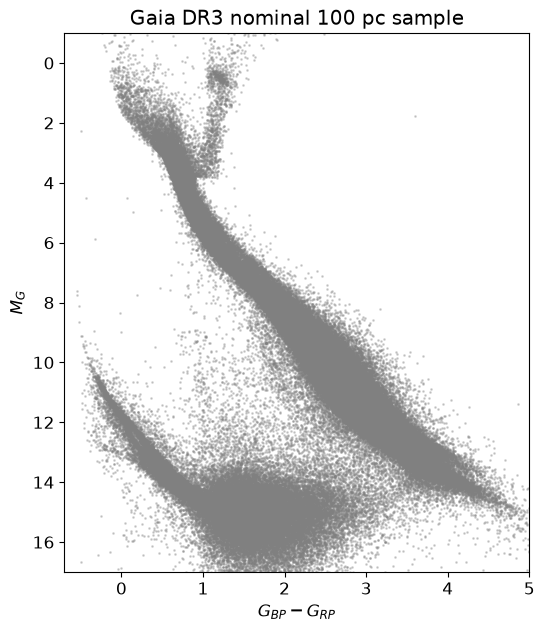

In [6]:
sample["mg"] = sample["phot_g_mean_mag"] + 5 * np.log10(sample["parallax"]) - 10

def hrd(ax, tab, **kw):
    kw = {"s": 1, "alpha": 0.3, "color": "0.5", **kw}
    ax.scatter(tab["bp_rp"], tab["mg"], **kw)
    ax.set_xlabel(r"$G_{BP}-G_{RP}$"); ax.set_ylabel(r"$M_G$")
    ax.set_xlim(-0.7, 5); ax.set_ylim(17, -1)

fig, ax = plt.subplots(figsize=(6, 7))
hrd(ax, sample)
ax.set_title("Gaia DR3 nominal 100 pc sample")
plt.show()

The TOPCAT tutorial defines three subsets. Here `phot_ok` is an analytic version of the hand-drawn cut
(the upper envelope of the BP/RP excess factor used by Gaia Collaboration, Babusiaux et al. 2018):

astrom_ok   253688  (83%)
ruwe_ok     228623  (75%)
phot_ok     263692  (86%)
ok          221197  (72%)


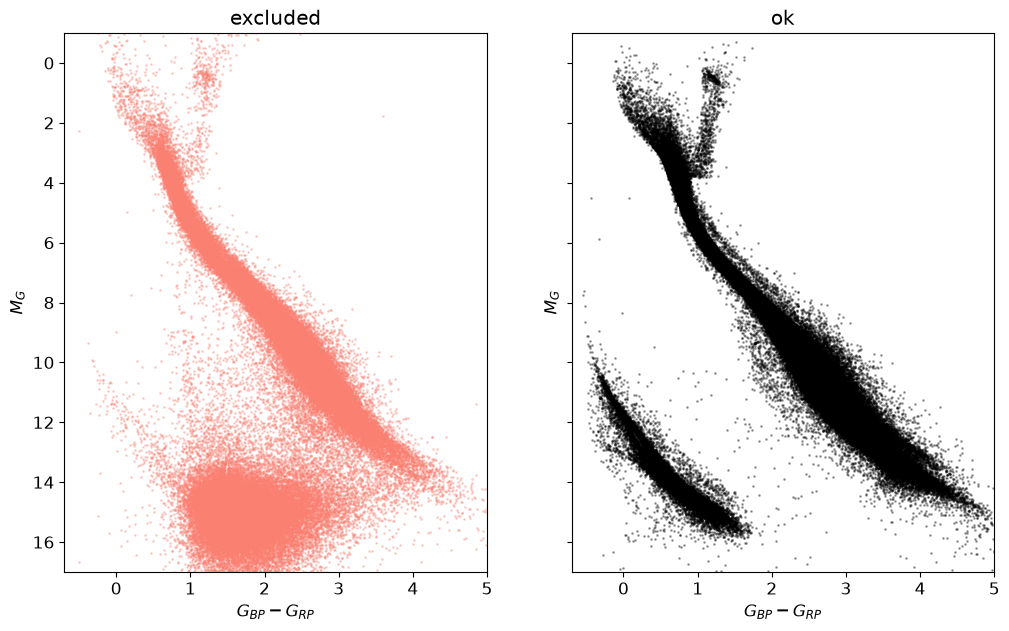

In [7]:
s = sample
astrom_ok = (s["astrometric_excess_noise"] < 1) | (s["astrometric_excess_noise_sig"] < 2)
ruwe_ok = s["ruwe"] < 1.4
phot_ok = s["phot_bp_rp_excess_factor"] < 1.3 + 0.06 * s["bp_rp"] ** 2
ok = np.asarray(astrom_ok & ruwe_ok & phot_ok)
for name, m in [("astrom_ok", astrom_ok), ("ruwe_ok", ruwe_ok), ("phot_ok", phot_ok), ("ok", ok)]:
    print(f"{name:10s} {np.sum(m):7d}  ({100*np.mean(m):.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
hrd(axes[0], s[~ok], color="salmon"); axes[0].set_title("excluded")
hrd(axes[1], s[ok], color="k"); axes[1].set_title("ok")
plt.show()

### A white dwarf subset

In TOPCAT the WD sequence is selected by hand with the blob tool. In code, we use the colour-magnitude cut of
[Gentile Fusillo et al. (2021)](https://ui.adsabs.harvard.edu/abs/2021MNRAS.508.3877G), $M_G > 6 + 5\,(G_{BP}-G_{RP})$, which
runs between the white dwarf sequence and the main sequence (their catalogue adds further cuts; the line alone is enough on the clean 100 pc sample):

15132 white dwarfs within 100 pc (clean), 140 within 20 pc


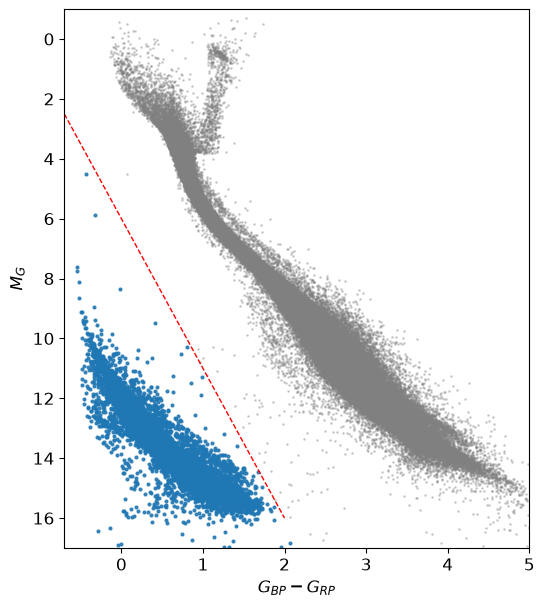

In [8]:
wd = ok & (s["mg"] > 6 + 5 * s["bp_rp"])       # below the line M_G = 6 + 5 (BP-RP) of Gentile Fusillo et al. (2021)
wd_20pc = wd & (s["parallax"] > 50)
print(f"{np.sum(wd)} white dwarfs within 100 pc (clean), {np.sum(wd_20pc)} within 20 pc")

fig, ax = plt.subplots(figsize=(6, 7))
hrd(ax, s[ok]); hrd(ax, s[wd], color="tab:blue", s=4, alpha=0.8)
x = np.linspace(-0.7, 2, 10); ax.plot(x, 6 + 5 * x, "r--", lw=1)
plt.show()

## 3. A cone search

`Gaia.cone_search` (or `cone_search_async` for large radii) returns every Gaia source within a radius of a position. Here: 15″ around WD 0426+588,
the WD+dM binary that the TOPCAT tutorial recovers as a wide pair.

In [9]:
coords = SkyCoord("04 31 15.33 +58 58 10.13", unit=(u.hourangle, u.deg), frame="icrs")
job = Gaia.cone_search(coords, radius=15 * u.arcsec)          # synchronous; use cone_search_async for big radii
cone = job.get_results()
with np.errstate(invalid="ignore"):                          # one neighbour has no parallax
    cone["mg"] = cone["phot_g_mean_mag"] + 5 * np.log10(cone["parallax"]) - 10
print(len(cone), "sources found")
cone[["source_id", "dist", "parallax", "pmra", "pmdec", "phot_g_mean_mag", "bp_rp", "mg", "has_xp_sampled", "has_rvs"]]

3 sources found


source_id,dist,parallax,pmra,pmdec,phot_g_mean_mag,bp_rp,mg,has_xp_sampled,has_rvs
,,mas,mas / yr,mas / yr,mag,mag,,,
int64,float64,float64,float64,float64,float32,float32,float64,bool,bool
470826482637310848,5.097290689662691e-06,181.2730074917688,1334.7796929514584,-1947.638150541708,12.33619,0.44229984,13.62785592453212,True,False
470826482630688640,0.0012143827211962164,-0.3590840386663102,1.812281733953923,-1.00557588516864,19.725304,1.2375679,--,False,False
470826482637310080,0.0028469011293135666,181.24383901243414,1300.3647836025643,-2046.1055188965706,9.702565,2.8958826,10.993881456194753,True,True


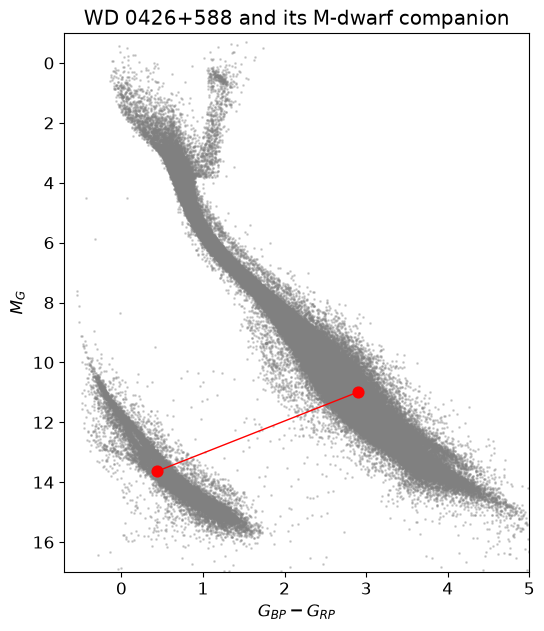

In [10]:
good = cone[cone["parallax_over_error"] > 5]
fig, ax = plt.subplots(figsize=(6, 7))
hrd(ax, s[ok])
ax.scatter(good["bp_rp"], good["mg"], s=60, c="r", zorder=3)
ax.plot(good["bp_rp"], good["mg"], "r-", lw=1)
ax.set_title("WD 0426+588 and its M-dwarf companion")
plt.show()

## 4. Cross-matching a local table (TAP upload)

The Gaia DR2 20 pc white dwarf sample of [Hollands et al. (2018)](https://ui.adsabs.harvard.edu/abs/2018MNRAS.480.3942H)
has DR2 source ids. To get the DR3 data we go through `gaiadr3.dr2_neighbourhood` (DR2 → DR3 ids), then join with
`gaiadr3.gaia_source`. The local table is uploaded with the query and referred to as `tap_upload.<name>`.

Both steps are slow joins against very large tables, so run them as asynchronous jobs (registered account),
or on the ARI-Gaia mirror as shown.

In [11]:
hollands = Table.read("data/table_20pc_WDs.csv", format="ascii.csv")
hollands.rename_column("Gaia DR2 ID", "dr2_source_id")      # ADQL needs a plain column name
hollands["dr2_source_id"] = hollands["dr2_source_id"].astype("int64")
for col in ("WD", "spType"):                                # tidy the string columns (some entries are blank/masked)
    hollands[col] = np.array([str(w).strip() for w in hollands[col].filled("")])
print(len(hollands), "white dwarfs"); hollands[:3]

139 white dwarfs


J2015.5,WD,dr2_source_id,parallax,parallax_error,pmra,pmra_error,pmdec,pmdec_error,G,G_error,Gbp,Gbp_error,Grp,Grp_error,spType,comp,Teff,Teff_error,logg,logg_error,Note
str18,str10,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str6,str4,int64,int64,float64,float64,str3
000211.59-431006.0,2359-434,4994877094997259264,119.98,0.03,613.64,0.04,-686.73,0.04,12.9137,0.0004,12.9943,0.0034,12.7015,0.0009,DAP,H,8464,21,8.36,0.01,--
000240.29-341351.4,0000-345,2312821266302222720,67.54,0.04,152.2,0.06,-762.18,0.06,14.8943,0.0005,15.1187,0.004,14.4948,0.002,DC,He,6327,29,8.14,0.01,--
000720.92+123017.6,0004+122,2766234439302571904,57.31,0.11,354.94,0.18,-232.26,0.11,16.265,0.0008,16.6828,0.0062,15.6775,0.0032,DC,He,5116,24,8.21,0.02,--


In [12]:
import pyvo

def tap_async(query, uploads=None, service="https://gaia.ari.uni-heidelberg.de/tap", maxrec=2_000_000):
    """Run an asynchronous TAP query with pyvo (uploads: {name: astropy Table}). Works on any TAP service."""
    svc = pyvo.dal.TAPService(service)
    job = svc.submit_job(query, uploads=uploads, maxrec=maxrec)
    job.run(); job.wait()
    job.raise_if_error()
    return job.fetch_result().to_table()

q_neigh = """
SELECT db.dr2_source_id, db.dr3_source_id, db.angular_distance, db.magnitude_difference, tc.WD, tc.spType
FROM gaiadr3.dr2_neighbourhood AS db
JOIN tap_upload.t1 AS tc ON db.dr2_source_id = tc.dr2_source_id
WHERE db.angular_distance < 5
"""
neigh = tap_async(q_neigh, uploads={"t1": hollands[["WD", "dr2_source_id", "spType"]]})
print(len(neigh), "DR3 counterparts for", len(set(neigh["dr2_source_id"])), "DR2 sources")

139 DR3 counterparts for 139 DR2 sources


139 rows; 74 with XP sampled spectra, 12 with epoch photometry, 0 with RVS spectra


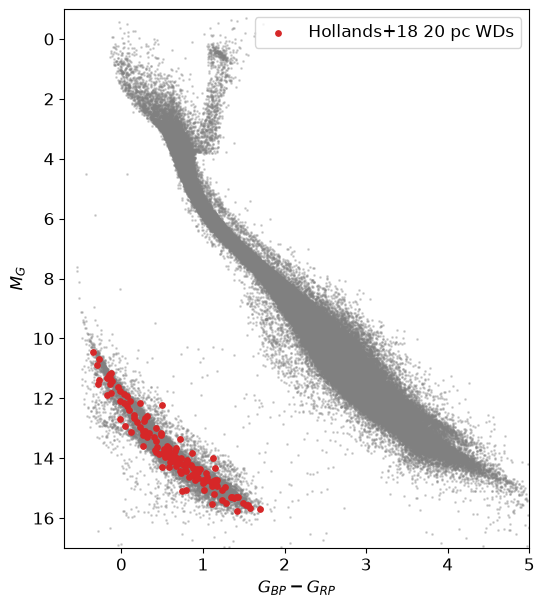

In [13]:
# The equivalent call on the ESA archive with astroquery (needs a registered account for the time limit):
# job = Gaia.launch_job_async(q_neigh, upload_resource=hollands[["WD", "dr2_source_id", "spType"]], upload_table_name="t1")
# neigh = job.get_results()

q_full = """
SELECT tc.WD, tc.spType, db.*
FROM gaiadr3.gaia_source AS db
JOIN tap_upload.t6 AS tc ON db.source_id = tc.dr3_source_id
"""
hollands_dr3 = tap_async(q_full, uploads={"t6": neigh})
hollands_dr3["mg"] = hollands_dr3["phot_g_mean_mag"] + 5 * np.log10(hollands_dr3["parallax"]) - 10
hollands_dr3 = hollands_dr3[np.argsort(hollands_dr3["WD"])]
print(len(hollands_dr3), "rows;",
      int(np.sum(hollands_dr3["has_xp_sampled"])), "with XP sampled spectra,",
      int(np.sum(hollands_dr3["has_epoch_photometry"])), "with epoch photometry,",
      int(np.sum(hollands_dr3["has_rvs"])), "with RVS spectra")

fig, ax = plt.subplots(figsize=(6, 7))
hrd(ax, s[ok]); ax.scatter(hollands_dr3["bp_rp"], hollands_dr3["mg"], s=15, c="tab:red", zorder=3, label="Hollands+18 20 pc WDs")
ax.legend(); plt.show()

## 5. Datalink: spectra and light curves

The bulky DR3 products (mean BP/RP spectra, RVS spectra, epoch photometry, MCMC samples) are **not** table columns.
Each source row carries flags (`has_xp_continuous`, `has_xp_sampled`, `has_rvs`, `has_epoch_photometry`, …) and the
products are fetched per source through the **Datalink** protocol. `Gaia.load_data` does that; it returns a dictionary
keyed by product file name.

- `retrieval_type`: `XP_SAMPLED`, `XP_CONTINUOUS`, `RVS`, `EPOCH_PHOTOMETRY`, `MCMC_GSPPHOT`, `MCMC_MSC`, or `ALL`.
- `data_structure`: `DATAMODEL_STANDARD` (one file per source and product, IVOA-style columns) or
  `DATAMODEL_GAIA` (one file per product, Gaia data-model columns). These replaced `INDIVIDUAL` / `RAW` in October 2026.
- At most 5000 sources per call for registered users, **50 for anonymous users** (since October 2026): log in, or split long lists into chunks.

Our three test sources: WD 0426+588, its M-dwarf companion, and G 29-38 (ZZ Psc), the pulsating DA white dwarf with a
debris disc, 17.5 pc away.

The helper below caches what it downloads as FITS files under `data/datalink/`, so the rest of the notebook (including
the GaiaXPy section) works offline once the files exist; the tutorial's data bundle ships them.

In [14]:
targets = {
    "WD 0426+588": 470826482637310848,
    "M dwarf companion": 470826482637310080,
    "G 29-38 (ZZ Psc)": 2660358032257156736,
}
def load_products(ids, cache_dir, retrieval_type="ALL"):
    # Datalink products for `ids`, cached as FITS files in `cache_dir` (one per product and source), so that the
    # notebook also runs when the archive is busy or in maintenance. Returns {file name: [Table]} like Gaia.load_data.
    cache_dir = Path(cache_dir)
    if not (cache_dir.is_dir() and any(cache_dir.glob("*.fits"))):
        fetched = Gaia.load_data(ids=list(ids), data_release="Gaia DR3", retrieval_type=retrieval_type,
                                 data_structure="DATAMODEL_STANDARD", format="votable")
        cache_dir.mkdir(parents=True, exist_ok=True)
        for key, tabs in fetched.items():
            tab = tabs[0]
            (tab.to_table() if hasattr(tab, "to_table") else tab).write(cache_dir / key.replace(".xml", ".fits"), overwrite=True)
    return {f.stem + ".xml": [Table.read(f)] for f in sorted(cache_dir.glob("*.fits"))}

products = load_products(targets.values(), "data/datalink")
for key in sorted(products):
    print(key)

EPOCH_PHOTOMETRY_Gaia_DR3_2660358032257156736.xml
RVS_Gaia_DR3_470826482637310080.xml
XP_CONTINUOUS_Gaia_DR3_2660358032257156736.xml
XP_CONTINUOUS_Gaia_DR3_470826482637310080.xml
XP_CONTINUOUS_Gaia_DR3_470826482637310848.xml
XP_SAMPLED_Gaia_DR3_2660358032257156736.xml
XP_SAMPLED_Gaia_DR3_470826482637310080.xml
XP_SAMPLED_Gaia_DR3_470826482637310848.xml


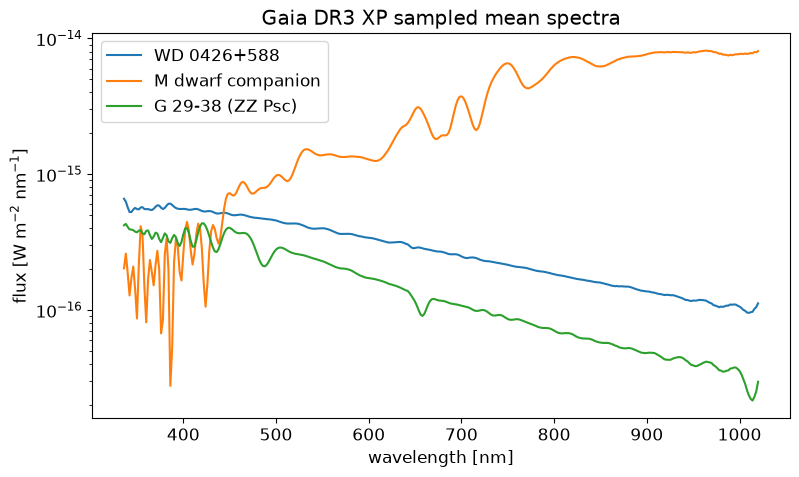

In [15]:
def get_product(products, retrieval_type, source_id):
    """Return the astropy Table of one Datalink product for one source."""
    key = f"{retrieval_type}_Gaia_DR3_{source_id}.xml"
    elem = products[key][0]
    return elem.to_table() if hasattr(elem, "to_table") else elem

fig, ax = plt.subplots(figsize=(9, 5))
for name, sid in targets.items():
    xp = get_product(products, "XP_SAMPLED", sid)
    ax.plot(xp["wavelength"], xp["flux"], label=name)
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel(r"flux [W m$^{-2}$ nm$^{-1}$]"); ax.set_yscale("log")
ax.legend(); ax.set_title("Gaia DR3 XP sampled mean spectra")
plt.show()

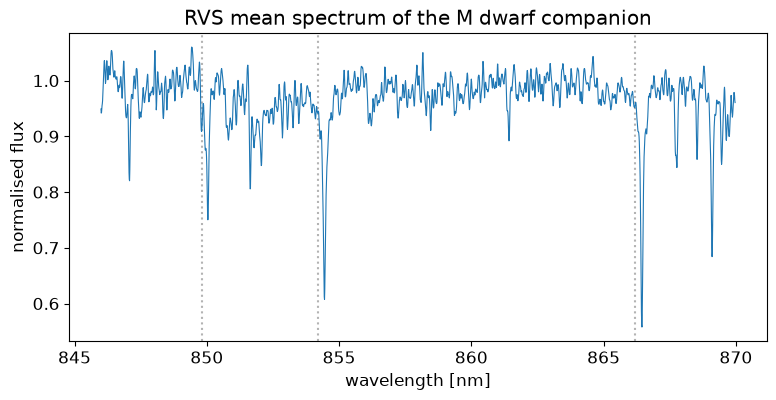

In [16]:
rvs = get_product(products, "RVS", targets["M dwarf companion"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rvs["wavelength"], rvs["flux"], lw=0.8)
for line in (849.8, 854.2, 866.2):   # Ca II infrared triplet
    ax.axvline(line, color="0.7", ls=":", zorder=0)
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("normalised flux"); ax.set_title("RVS mean spectrum of the M dwarf companion")
plt.show()

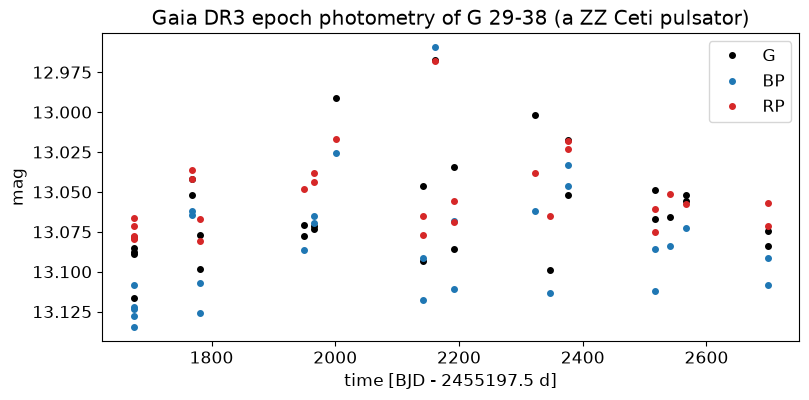

In [17]:
lc = get_product(products, "EPOCH_PHOTOMETRY", targets["G 29-38 (ZZ Psc)"])
lc = lc[~lc["rejected_by_photometry"]]
fig, ax = plt.subplots(figsize=(9, 4))
for band, col in (("g", "k"), ("bp", "tab:blue"), ("rp", "tab:red")):
    t = lc[f"{band}_transit_time" if band == "g" else f"{band}_obs_time"]
    m = lc[f"{band}_transit_mag" if band == "g" else f"{band}_mag"]
    ax.plot(t, m, "o", ms=4, color=col, label=band.upper())
ax.invert_yaxis(); ax.set_xlabel("time [BJD - 2455197.5 d]"); ax.set_ylabel("mag"); ax.legend()
ax.set_title("Gaia DR3 epoch photometry of G 29-38 (a ZZ Ceti pulsator)")
plt.show()

### Datalink without astroquery

The same products are plain HTTP downloads, which is handy for scripts in any language:

```
https://gea.esac.esa.int/data-server/data?RETRIEVAL_TYPE=XP_SAMPLED&RELEASE=Gaia+DR3&ID=Gaia+DR3+2660358032257156736&DATA_STRUCTURE=DATAMODEL_STANDARD&FORMAT=csv
```

and the list of products available for a source (the *links* table TOPCAT shows) is

```
https://gea.esac.esa.int/data-server/datalink/links?ID=Gaia+DR3+2660358032257156736
```

In [18]:
import io, requests
url = ("https://gea.esac.esa.int/data-server/data?RETRIEVAL_TYPE=XP_SAMPLED&RELEASE=Gaia+DR3"
       "&ID=Gaia+DR3+2660358032257156736&DATA_STRUCTURE=DATAMODEL_STANDARD&FORMAT=csv")
xp_csv = pd.read_csv(io.StringIO(requests.get(url, timeout=60).text))
xp_csv.head()

,source_id,solution_id,ra,dec,wavelength,flux,flux_error
0,2660358032257156736,4545469030156206081,352.196708,5.247213,336.0,4.201819e-16,5.135392e-17
1,2660358032257156736,4545469030156206081,352.196708,5.247213,338.0,4.301561e-16,4.241243e-17
2,2660358032257156736,4545469030156206081,352.196708,5.247213,340.0,4.090279e-16,3.820801e-17
3,2660358032257156736,4545469030156206081,352.196708,5.247213,342.0,3.919068e-16,3.621097e-17
4,2660358032257156736,4545469030156206081,352.196708,5.247213,344.0,3.909603e-16,3.653013e-17


## 6. GaiaXPy: working with the XP continuous spectra

The *continuous* mean spectra are the native DR3 product: coefficients of a basis-function expansion, from which
any sampling can be reconstructed. [GaiaXPy](https://gaia-dpci.github.io/GaiaXPy-website/) is the DPAC package for them
(docs: https://gaiaxpy.readthedocs.io). Its four tools:

| tool | what it does |
|---|---|
| `calibrate` | absolute flux vs. wavelength (W m⁻² nm⁻¹), on any sampling you choose |
| `convert` | internally calibrated spectra in pseudo-wavelength (the instrument's own system) |
| `generate` | synthetic photometry in many systems (SDSS, Johnson-Kron-Cousins, PanSTARRS, LSST, …) |
| `plot_spectra` | quick-look plots of the above |

Input can be a list of source ids (GaiaXPy queries the archive for you), an ADQL query string, a file downloaded
from the archive, or a DataFrame in the archive's layout. Use `save_file=False` to keep results in memory.

Here we take the DataFrame route with the XP *continuous* spectra already fetched (and cached) in section 5, so this
section needs no live archive access. The one-liner `calibrate(ids, save_file=False)` does the same with a live query,
and fails with an HTTP 503 whenever the archive is in maintenance.

In [19]:
from gaiaxpy import calibrate, convert, generate, plot_spectra, PhotometricSystem

ids = list(targets.values())
xp_cont = vstack([get_product(products, "XP_CONTINUOUS", sid) for sid in ids]).to_pandas()   # archive layout, one row per source
# calibrated, sampling = calibrate(ids, save_file=False)            # the live-archive alternative
calibrated, sampling = calibrate(xp_cont, save_file=False)   # default sampling: 336-1020 nm in 2 nm steps
print(calibrated.columns.tolist()); print("sampling:", sampling[:3], "...", sampling[-3:], f"({len(sampling)} points)")

Calibrating data:   0%|          | 0/3 [00:00<?, ?spec/s]

['source_id', 'flux', 'flux_error']
sampling: [336. 338. 340.] ... [1016. 1018. 1020.] (343 points)


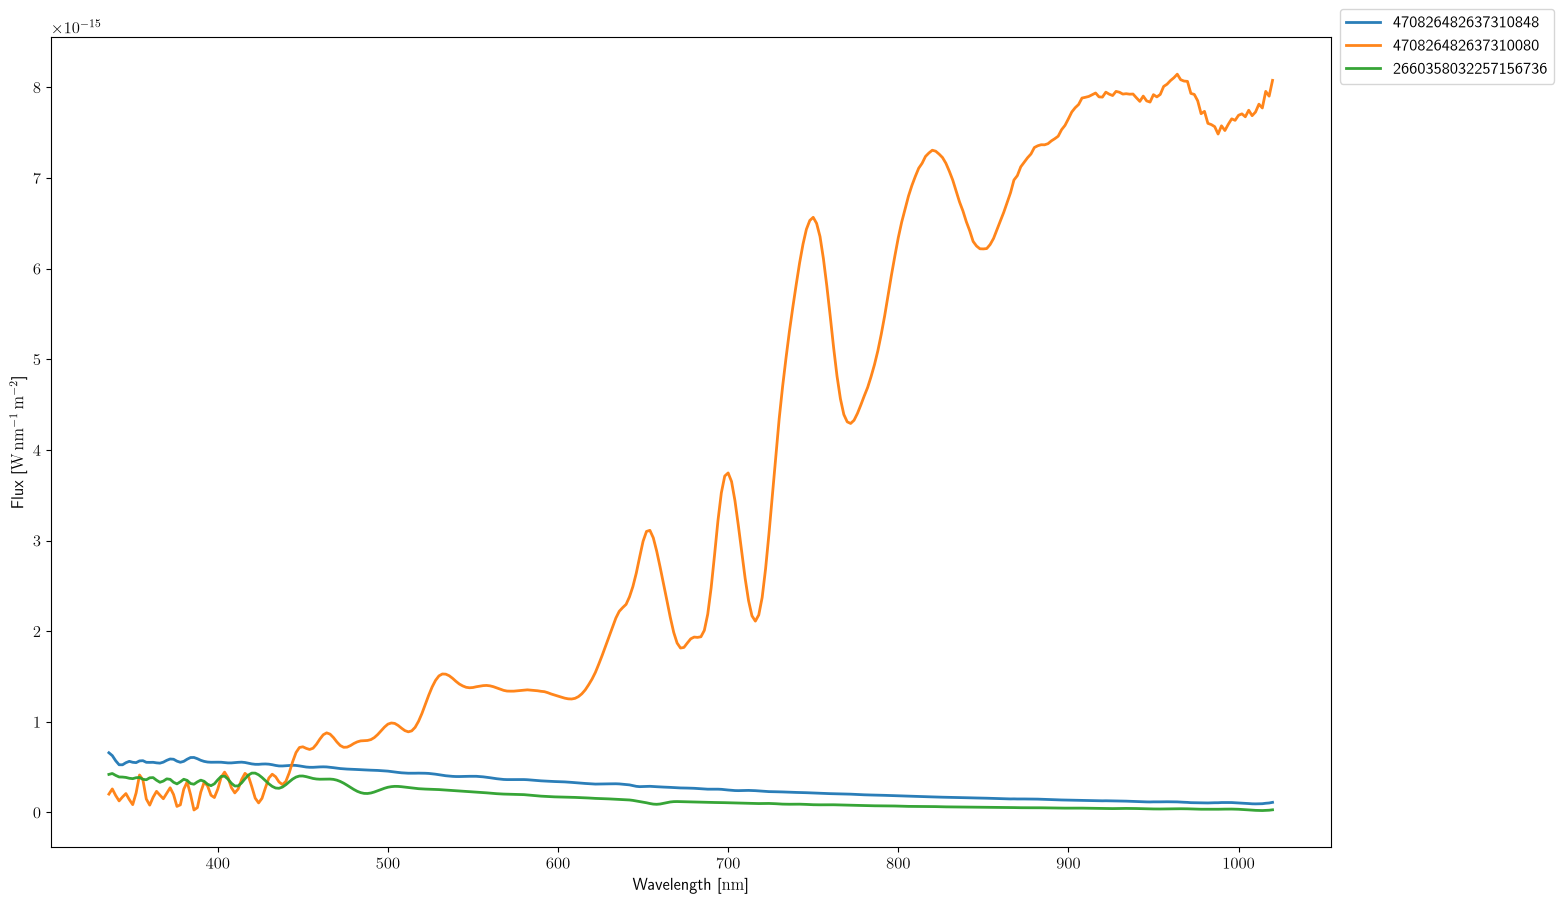

In [20]:
plot_spectra(calibrated, sampling=sampling, multi=True, show_plot=True, legend=True)
plt.rc("text", usetex=False)   # GaiaXPy >= 2.1.3 switches matplotlib to LaTeX labels; switch back for our own plots

Calibrating data:   0%|          | 0/3 [00:00<?, ?spec/s]

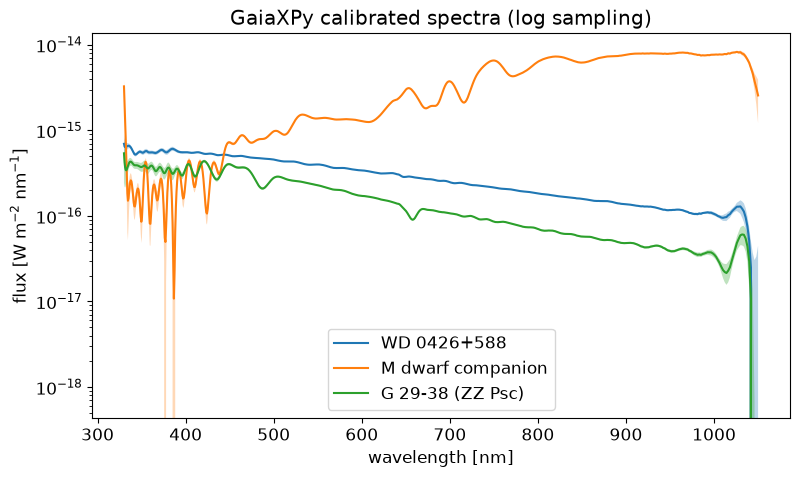

In [21]:
# A finer, logarithmic sampling that resolves the blue end better
calibrated_log, sampling_log = calibrate(xp_cont, sampling=np.geomspace(330, 1049.99, 600), save_file=False)
fig, ax = plt.subplots(figsize=(9, 5))
for (name, sid) in targets.items():
    row = calibrated_log[calibrated_log.source_id == sid].iloc[0]
    ax.plot(sampling_log, row["flux"], label=name)
    ax.fill_between(sampling_log, row["flux"] - row["flux_error"], row["flux"] + row["flux_error"], alpha=0.3)
ax.set_yscale("log"); ax.set_xlabel("wavelength [nm]"); ax.set_ylabel(r"flux [W m$^{-2}$ nm$^{-1}$]"); ax.legend()
ax.set_title("GaiaXPy calibrated spectra (log sampling)"); plt.show()

In [22]:
# Internally calibrated spectra (pseudo-wavelength, separate BP and RP)
converted, pw_sampling = convert(xp_cont, save_file=False)
converted[["source_id", "xp"]]

Converting data:   0%|          | 0/3 [00:00<?, ?spec/s]

,source_id,xp
0,470826482637310848,BP
1,470826482637310848,RP
2,470826482637310080,BP
3,470826482637310080,RP
4,2660358032257156736,BP
5,2660358032257156736,RP


In [23]:
# Synthetic photometry
synth = generate(xp_cont, photometric_system=[PhotometricSystem.SDSS, PhotometricSystem.JKC, PhotometricSystem.Gaia_DR3_Vega],
                 save_file=False)
mag_cols = [c for c in synth.columns if "_mag_" in c]
synth.set_index("source_id")[mag_cols].T.round(3)

Generating photometry:   0%|          | 0/3 [00:00<?, ?spec/s]

source_id,470826482637310848,470826482637310080,2660358032257156736
Sdss_mag_u,13.009,13.951,13.499
Sdss_mag_g,12.527,11.998,13.024
Sdss_mag_r,12.373,10.478,13.171
Sdss_mag_i,12.391,9.015,13.365
Sdss_mag_z,12.477,8.198,13.595
Jkc_mag_U,12.238,13.235,12.735
Jkc_mag_B,12.726,12.699,13.199
Jkc_mag_V,12.421,11.101,13.026
Jkc_mag_R,12.203,9.804,13.038
Jkc_mag_I,12.000,8.221,13.028


In [24]:
# Sanity check: synthetic Gaia G from the XP spectrum vs. the catalogue G
cat_tab = Gaia.launch_job("SELECT source_id, phot_g_mean_mag FROM gaiadr3.gaia_source WHERE source_id IN ("
                          + ",".join(map(str, targets.values())) + ")").get_results()
cat = {int(sid): float(g) for sid, g in zip(cat_tab["source_id"], cat_tab["phot_g_mean_mag"])}
for name, sid in targets.items():
    g_syn = synth.loc[synth.source_id == sid, "GaiaDr3Vega_mag_G"].iloc[0]
    print(f"{name:20s}  G_cat = {cat[sid]:.3f}   G_synth = {g_syn:.3f}   diff = {1000*(g_syn-cat[sid]):+.0f} mmag")

WD 0426+588           G_cat = 12.336   G_synth = 12.339   diff = +3 mmag
M dwarf companion     G_cat = 9.703   G_synth = 9.683   diff = -20 mmag
G 29-38 (ZZ Psc)      G_cat = 13.062   G_synth = 13.070   diff = +8 mmag


In [25]:
print(PhotometricSystem.get_available_systems())

DECam, Els_Custom_W09_S2, Euclid_VIS, Gaia_2, Gaia_DR3_Vega, Halpha_Custom_AB, H_Custom, Hipparcos_Tycho, HST_ACSWFC, HST_HUGS_Std, HST_WFC3UVIS, HST_WFPC2, IPHAS, JKC, JKC_Std, JPAS, JPLUS, JWST_NIRCAM, LSST, PanSTARRS1, PanSTARRS1_Std, Pristine, SDSS, SDSS_Std, Sky_Mapper, Stromgren, Stromgren_Std, WFIRST


## Exercise solutions

### B. Epoch photometry of an RR Lyrae star

`gaiadr3.vari_rrlyrae` holds the RR Lyrae classifications and periods (`pf` = fundamental period in days).
Take RR Lyr itself, fetch its epoch photometry through Datalink and fold it on the catalogue period.

The *old* sub-task (exclude a locally stored list of ids with `NOT IN (SELECT ... FROM tap_upload.t1)`) is kept at the end.

In [26]:
rrl = Gaia.launch_job("""
SELECT v.source_id, v.pf, v.best_classification, v.num_clean_epochs_g, v.int_average_g, v.peak_to_peak_g, v.epoch_g
FROM gaiadr3.vari_rrlyrae AS v
WHERE v.source_id = 2125982599343482624
""").get_results()
rrl

source_id,pf,best_classification,num_clean_epochs_g,int_average_g,peak_to_peak_g,epoch_g
,d,,,mag,mag,d
int64,float64,object,int16,float32,float32,float64
2125982599343482624,0.5667732268824381,RRab,37,7.6430144,0.80206287,1765.229463076698


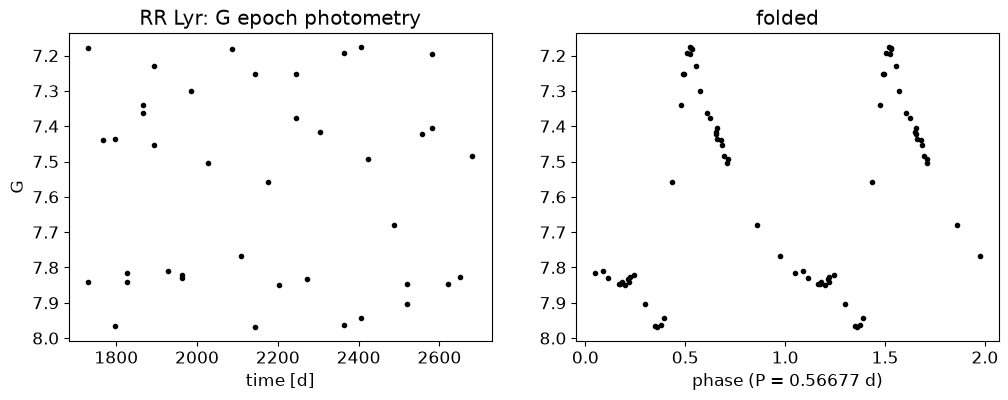

In [27]:
rr_id = int(rrl["source_id"][0]); period = float(rrl["pf"][0])
rr_products = load_products([rr_id], "data/datalink_rrlyr", retrieval_type="EPOCH_PHOTOMETRY")
rr_lc = get_product(rr_products, "EPOCH_PHOTOMETRY", rr_id)
rr_lc = rr_lc[~rr_lc["rejected_by_photometry"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rr_lc["g_transit_time"], rr_lc["g_transit_mag"], "k.")
axes[0].invert_yaxis(); axes[0].set_xlabel("time [d]"); axes[0].set_ylabel("G"); axes[0].set_title("RR Lyr: G epoch photometry")
phase = (np.asarray(rr_lc["g_transit_time"]) / period) % 1
for ph in (phase, phase + 1):
    axes[1].plot(ph, rr_lc["g_transit_mag"], "k.")
axes[1].invert_yaxis(); axes[1].set_xlabel(f"phase (P = {period:.5f} d)"); axes[1].set_title("folded")
plt.show()

In [28]:
# The old sub-task: retrieve a table while excluding ids listed in a local table (here: our three Datalink targets).
exclude = Table({"source_id": list(targets.values())})
q = """
SELECT TOP 5 g.source_id, g.parallax, g.phot_g_mean_mag
FROM gaiadr3.gaia_source AS g
WHERE g.parallax > 150
AND g.source_id NOT IN (SELECT tc.source_id FROM tap_upload.t1 AS tc)
ORDER BY parallax DESC
"""
# On the ESA archive this is Gaia.launch_job_async(q, upload_resource=exclude, upload_table_name="t1") when logged in;
# here we run it on the ARI-Gaia mirror with the helper from section 4.
tap_async(q, uploads={"t1": exclude})

source_id,parallax,phot_g_mean_mag
,mas,mag
int64,float64,float32
5853498713190525696,768.0665391873573,8.984749
4472832130942575872,546.975939730948,8.1939745
3864972938605115520,415.17941567802137,11.038391
762815470562110464,392.75294543876464,6.551172
2947050466531873024,374.48958852876103,8.524133


### C. Wide binaries around the 20 pc white dwarfs

Repeat the TOPCAT multicone search in ADQL: for every Hollands et al. (2018) white dwarf (now with DR3 data), find Gaia
sources within a projected separation of 100 AU, i.e. within an angular radius $\theta = 100\,\mathrm{AU} \times \varpi$
($\theta$ in arcsec for $\varpi$ in arcsec; `1e-3 * 100 * parallax` arcsec for parallax in mas). Then apply the same
quality, parallax-consistency and velocity cuts as in the TOPCAT tutorial.

Note the `'ICRS'` first argument of `POINT`/`CIRCLE`: the ESA archive accepts the newer form without it, but ADQL 2.0 services such as the ARI mirror require it, so this form works everywhere. Also, `ORDER BY` accepts only plain column names, not `table.column`.

In [29]:
wd_in = hollands_dr3[["WD", "source_id", "ra", "dec", "parallax", "parallax_error", "pmra", "pmdec"]]
wd_in.rename_columns(["source_id", "ra", "dec", "parallax", "parallax_error", "pmra", "pmdec"],
                     ["wd_source_id", "wd_ra", "wd_dec", "wd_parallax", "wd_parallax_error", "wd_pmra", "wd_pmdec"])
wd_in["cone_radius_deg"] = 1e-3 * 100 * wd_in["wd_parallax"] / 3600      # 100 AU in degrees (ADQL wants a plain column here)
q_pairs = """
SELECT tc.*, g.source_id, g.parallax, g.parallax_error, g.parallax_over_error, g.pmra, g.pmdec,
       g.phot_g_mean_mag, g.bp_rp, g.ruwe, g.astrometric_excess_noise, g.astrometric_excess_noise_sig,
       g.phot_bp_mean_flux_over_error, g.phot_rp_mean_flux_over_error,
       DISTANCE(POINT('ICRS', tc.wd_ra, tc.wd_dec), POINT('ICRS', g.ra, g.dec)) * 3600 AS sep_arcsec
FROM tap_upload.t1 AS tc
JOIN gaiadr3.gaia_source AS g
  ON 1 = CONTAINS(POINT('ICRS', g.ra, g.dec), CIRCLE('ICRS', tc.wd_ra, tc.wd_dec, tc.cone_radius_deg))
WHERE g.source_id <> tc.wd_source_id
"""
pairs = tap_async(q_pairs, uploads={"t1": wd_in})
print(len(pairs), "neighbours within 100 AU (projected) of", len(set(pairs["WD"])), "white dwarfs")

117 neighbours within 100 AU (projected) of 33 white dwarfs


In [30]:
p = pairs
quality = ((p["parallax_over_error"] > 10) & (p["phot_bp_mean_flux_over_error"] > 10) & (p["phot_rp_mean_flux_over_error"] > 10)
           & ((p["astrometric_excess_noise"] < 1) | (p["astrometric_excess_noise_sig"] < 2)) & (p["ruwe"] < 1.4))
p["s_pc"] = p["sep_arcsec"] / p["wd_parallax"] * 1000 / 206265          # projected separation in pc (small-angle)
# parallax consistency (El-Badry & Rix 2018): |1/plx1 - 1/plx2| - 2 s  <=  3 sigma  (distances in pc, parallaxes in mas)
d_diff = np.abs(1000 / p["wd_parallax"] - 1000 / p["parallax"])
sigma = 1000 * np.sqrt(p["wd_parallax_error"] ** 2 / p["wd_parallax"] ** 4 + p["parallax_error"] ** 2 / p["parallax"] ** 4)
within_parallax = d_diff - 2 * p["s_pc"] <= 3 * sigma
# tangential velocity difference and the circular-orbit limit for a 1 Msun binary
p["dv_tan"] = 4.7405 * np.hypot(p["pmra"] - p["wd_pmra"], p["pmdec"] - p["wd_pmdec"]) / p["wd_parallax"]
p["s_au"] = p["s_pc"] * 206265
v_orb_max = 29.78 / np.sqrt(p["s_au"])
candidates = p[np.asarray(quality & within_parallax & (p["dv_tan"] < 2 * v_orb_max))]
print(f"{np.sum(quality)} pass the quality cuts, {np.sum(quality & within_parallax)} also have consistent parallaxes,"
      f" {len(candidates)} also have consistent velocities")
candidates[["WD", "wd_source_id", "source_id", "sep_arcsec", "s_au", "parallax", "wd_parallax", "dv_tan", "phot_g_mean_mag", "bp_rp"]]

3 pass the quality cuts, 1 also have consistent parallaxes, 1 also have consistent velocities


WD,wd_source_id,source_id,sep_arcsec,s_au,parallax,wd_parallax,dv_tan,phot_g_mean_mag,bp_rp
,,,,,mas,mas,,mag,mag
object,int64,int64,float64,float64,float64,float64,float64,float32,float32
0426+588,470826482637310848,470826482637310080,10.263094359087761,56.61678206311982,181.24383901243414,181.2730074917688,2.7277817662359736,9.702565,2.8958826


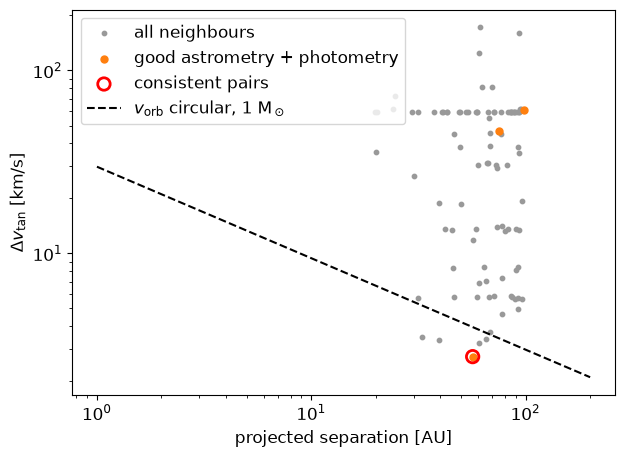

In [31]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(p["s_au"], p["dv_tan"], s=10, c="0.6", label="all neighbours")
ax.scatter(p["s_au"][quality], p["dv_tan"][quality], s=25, c="tab:orange", label="good astrometry + photometry")
ax.scatter(candidates["s_au"], candidates["dv_tan"], s=80, facecolors="none", edgecolors="r", lw=2, label="consistent pairs")
xx = np.geomspace(1, 200, 50); ax.plot(xx, 29.78 / np.sqrt(xx), "k--", label=r"$v_{\rm orb}$ circular, 1 M$_\odot$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("projected separation [AU]"); ax.set_ylabel(r"$\Delta v_{\rm tan}$ [km/s]")
ax.legend(); plt.show()

### G. Synthetic SDSS photometry of the 20 pc white dwarfs

Use GaiaXPy to generate SDSS *ugriz* magnitudes from the XP spectra of the Hollands et al. (2018) white dwarfs
(all 139 have XP continuous spectra; we fetch them once through Datalink, 50 at a time, and keep the file), and plot a $u-g$ vs. $g-r$ colour-colour diagram coloured by the spectral type from the
local table. DA white dwarfs (hydrogen atmospheres) separate from the non-DA types because of the Balmer jump that falls
between *u* and *g*.

139 XP continuous spectra; ['source_id', 'solution_id', 'bp_basis_function_id', 'bp_degrees_of_freedom', 'bp_n_parameters', 'bp_n_measurements'] ...


Generating photometry:   0%|          | 0/139 [00:00<?, ?spec/s]

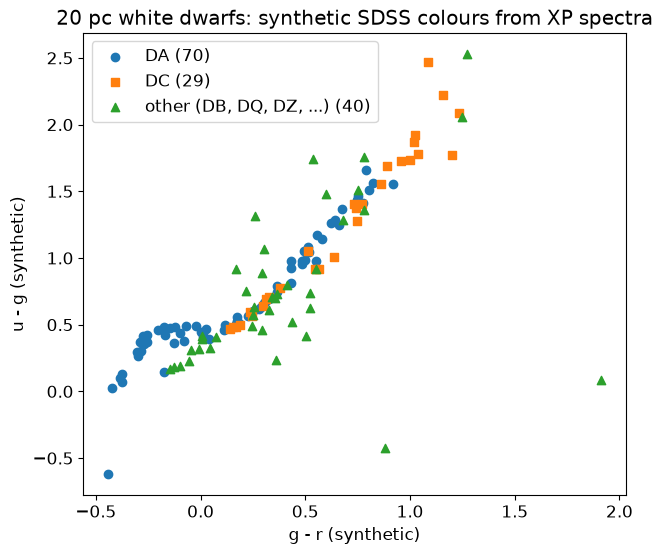

In [32]:
has_xp = hollands_dr3[np.asarray(hollands_dr3["has_xp_continuous"]).astype(bool)]
import os

def xp_continuous(ids, cache_file, n=50):
    # Fetch the XP continuous spectra of `ids` through Datalink (Gaia data-model layout, one row per source),
    # in chunks of `n` (anonymous Datalink requests are limited to 50 sources since Oct 2026), and cache the
    # result as a FITS file so the download happens once. Returns an astropy Table.
    if os.path.exists(cache_file):
        return Table.read(cache_file)
    parts = []
    for i in range(0, len(ids), n):
        d = Gaia.load_data(ids=list(ids[i:i + n]), data_release="Gaia DR3", retrieval_type="XP_CONTINUOUS",
                           data_structure="DATAMODEL_GAIA", format="votable")
        tab = list(d.values())[0][0]
        parts.append(tab.to_table() if hasattr(tab, "to_table") else tab)
    full = vstack(parts, metadata_conflicts="silent")
    full.write(cache_file, overwrite=True)
    return full

xpc_wd = xp_continuous(list(map(int, has_xp["source_id"])), "data/xp_continuous_20pc_wds.fits")
print(len(xpc_wd), "XP continuous spectra;", xpc_wd.colnames[:6], "...")
# GaiaXPy accepts the archive layout as a DataFrame: no further archive access needed
sdss = generate(xpc_wd.to_pandas(), photometric_system=PhotometricSystem.SDSS, save_file=False)
sdss = sdss.merge(has_xp[["source_id", "WD", "spType", "bp_rp", "mg"]].to_pandas(), on="source_id")   # WD names repeat for double degenerates, so merge on source_id
sdss["class"] = np.where(sdss.spType.str.startswith("DA"), "DA", np.where(sdss.spType.str.startswith("DC"), "DC", "other (DB, DQ, DZ, ...)"))
fig, ax = plt.subplots(figsize=(7, 6))
for cls, mk in (("DA", "o"), ("DC", "s"), ("other (DB, DQ, DZ, ...)", "^")):
    sel = sdss["class"] == cls
    ax.scatter(sdss.Sdss_mag_g[sel] - sdss.Sdss_mag_r[sel], sdss.Sdss_mag_u[sel] - sdss.Sdss_mag_g[sel], marker=mk, label=f"{cls} ({sel.sum()})")
ax.set_xlabel("g - r (synthetic)"); ax.set_ylabel("u - g (synthetic)"); ax.legend(); ax.set_title("20 pc white dwarfs: synthetic SDSS colours from XP spectra")
plt.show()

### H. Emission lines in XP spectra: cataclysmic variables vs. white dwarfs

Even at the low resolution of XP spectra, strong Hα emission is detectable. Following the idea of the *Gaia emission-line
magnitude* diagram of [Galiullin et al. (2026)](https://ui.adsabs.harvard.edu/abs/2026arXiv260100000G), compare the flux in a
window around Hα (656.3 nm) with the neighbouring continuum, for ten well-known cataclysmic variables and for our white dwarfs.

Calibrating data:   0%|          | 0/9 [00:00<?, ?spec/s]

Calibrating data:   0%|          | 0/139 [00:00<?, ?spec/s]

WZ Sge     H-alpha index = 2.00
U Gem      H-alpha index = 1.74
EX Hya     H-alpha index = 1.72
AM Her     H-alpha index = 1.68
SS Cyg     H-alpha index = 1.33
RX And     H-alpha index = 1.27
GK Per     H-alpha index = 1.14
TT Ari     H-alpha index = 1.03
IX Vel     H-alpha index = 0.99
white dwarfs: median 0.97, max 1.05


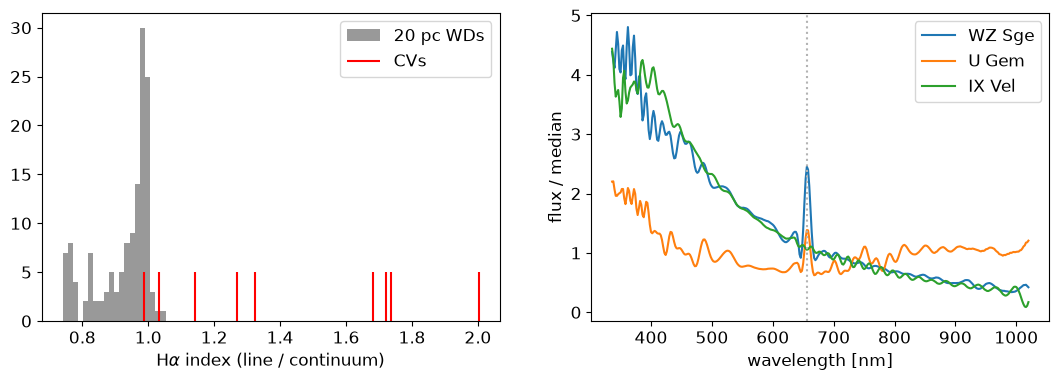

In [33]:
cvs = {"SS Cyg": 1972957892448494592, "AM Her": 2123837555230207744, "GK Per": 238540495056450048, "RX And": 374510294830244992,
       "IX Vel": 5515820034889610112, "V3885 Sgr": 6688624794231054976, "TT Ari": 78395045917118976, "EX Hya": 6185040879503491584,
       "WZ Sge": 1809844934461976832, "U Gem": 674214551557961984}
xpc_cv = xp_continuous(list(cvs.values()), "data/xp_continuous_cvs.fits")
cal_cv, samp = calibrate(xpc_cv.to_pandas(), save_file=False)
plt.rc("text", usetex=False)

def halpha_index(flux, wl):
    line = (wl > 650) & (wl < 662)
    cont = ((wl > 630) & (wl < 645)) | ((wl > 668) & (wl < 685))
    return np.nanmean(flux[line]) / np.nanmean(flux[cont])

cal_wd, _ = calibrate(xpc_wd.to_pandas(), save_file=False)
idx_cv = {name: halpha_index(np.asarray(cal_cv.loc[cal_cv.source_id == sid, "flux"].iloc[0]), samp) for name, sid in cvs.items() if (cal_cv.source_id == sid).any()}
idx_wd = [halpha_index(np.asarray(f), samp) for f in cal_wd["flux"]]
for name, v in sorted(idx_cv.items(), key=lambda kv: -kv[1]):
    print(f"{name:10s} H-alpha index = {v:.2f}")
print(f"white dwarfs: median {np.median(idx_wd):.2f}, max {np.max(idx_wd):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(idx_wd, bins=20, color="0.6", label="20 pc WDs"); axes[0].vlines(list(idx_cv.values()), 0, 5, color="r", label="CVs")
axes[0].set_xlabel(r"H$\alpha$ index (line / continuum)"); axes[0].legend()
for name in ("WZ Sge", "U Gem", "IX Vel"):
    row = cal_cv[cal_cv.source_id == cvs[name]].iloc[0]; axes[1].plot(samp, row["flux"] / np.nanmedian(row["flux"]), label=name)
axes[1].axvline(656.3, color="0.7", ls=":"); axes[1].set_xlabel("wavelength [nm]"); axes[1].set_ylabel("flux / median"); axes[1].legend()
plt.show()